# House Prices: Advanced Regression Techniques
### Mã nguồn - Nhóm 19, SGU
Dự đoán giá nhà Ames, Iowa bằng Random Forest & Gradient Boosting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
sns.set_style('whitegrid')
%matplotlib inline

## 1. Load Data

In [2]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
print(train.shape, test.shape)

(1460, 81) (1459, 80)


## 2. EDA

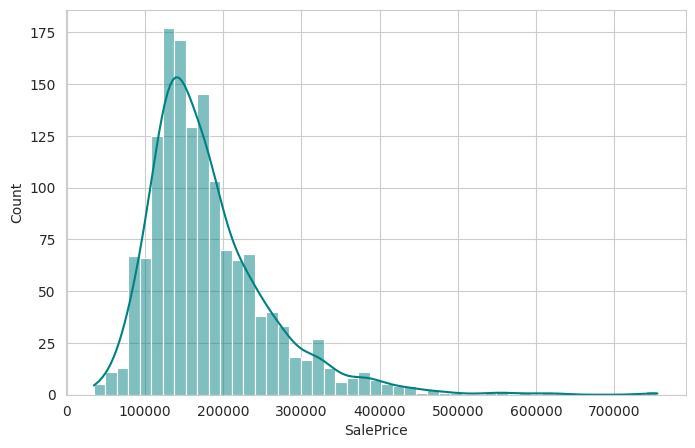

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [3]:
plt.figure(figsize=(8,5)); sns.histplot(train['SalePrice'], kde=True, color='teal'); plt.show()
train['SalePrice'].describe()

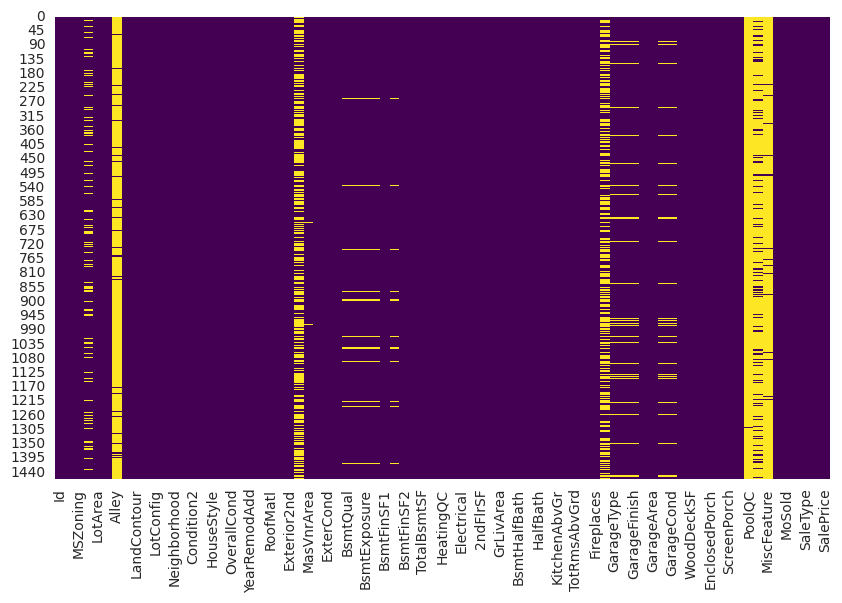

In [4]:
plt.figure(figsize=(10,6)); sns.heatmap(train.isnull(), cbar=False, cmap='viridis'); plt.show()

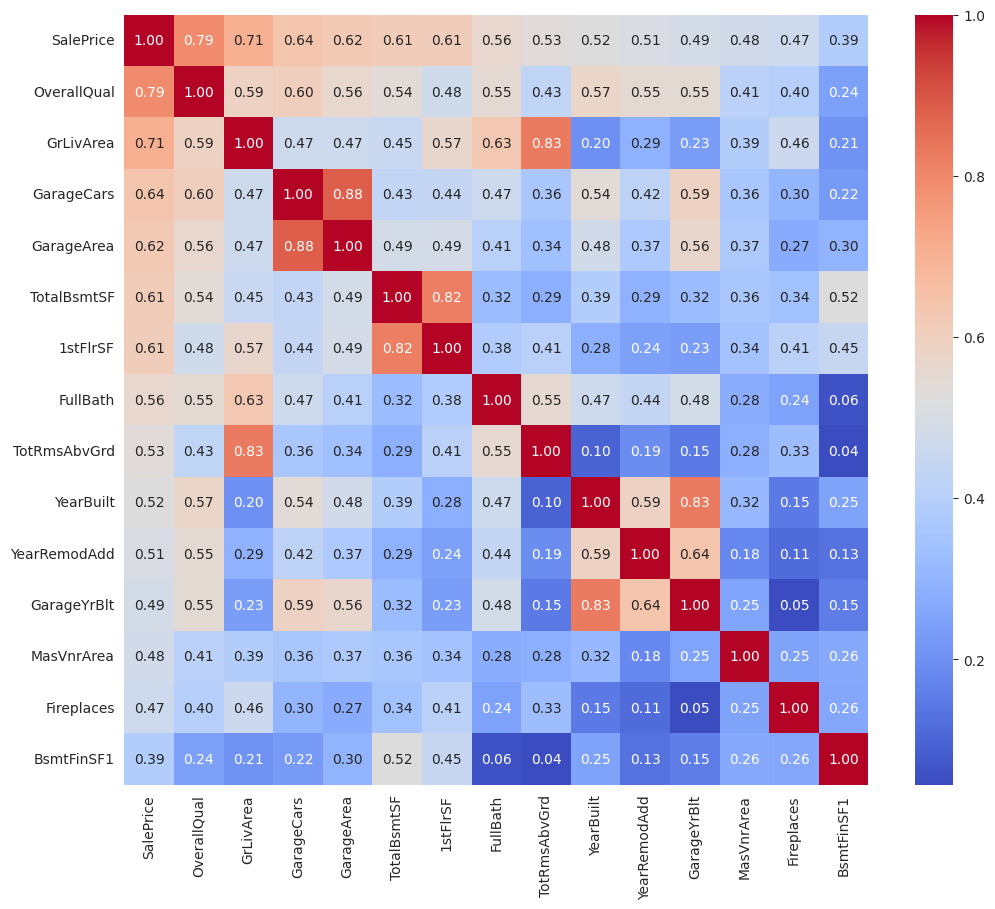

In [5]:
num_train = train.select_dtypes(include=[np.number])
corr = num_train.corr()
top = corr['SalePrice'].abs().sort_values(ascending=False).head(15).index
plt.figure(figsize=(12,10)); sns.heatmap(train[top].corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.show()

## 3. Xử lý NULL

In [6]:
cols_to_drop = ['Alley','PoolQC','Fence','MiscFeature','Id']
y = train['SalePrice'].copy(); test_ids = test['Id'].copy()
train_feat = train.drop(columns=cols_to_drop+['SalePrice'], errors='ignore')
test_feat = test.drop(columns=cols_to_drop, errors='ignore')
def fill_missing(df):
    df = df.copy()
    for c in df.select_dtypes(include=[np.number]).columns:
        if df[c].isnull().any(): df[c]=df[c].fillna(df[c].mean())
    for c in df.select_dtypes(exclude=[np.number]).columns:
        if df[c].isnull().any(): df[c]=df[c].fillna(df[c].mode()[0])
    return df
train_feat = fill_missing(train_feat); test_feat = fill_missing(test_feat)
print(train_feat.isnull().sum().sum(), test_feat.isnull().sum().sum())

0 0


## 4. One-Hot Encoding

In [7]:
n_train = train_feat.shape[0]
combined = pd.concat([train_feat, test_feat], axis=0, ignore_index=True)
cat_cols = combined.select_dtypes(exclude=[np.number]).columns.tolist()
combined_encoded = pd.get_dummies(combined, columns=cat_cols, drop_first=True)
X_train_full = combined_encoded.iloc[:n_train,:].reset_index(drop=True)
X_test_final = combined_encoded.iloc[n_train:,:].reset_index(drop=True)
print(X_train_full.shape, X_test_final.shape)

(1460, 235) (1459, 235)


## 5. Train/Validation Split

In [8]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train_full, y, test_size=0.2, random_state=42)

## 6. Modeling: Random Forest

In [9]:
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)
rf_pred = rf.predict(X_val)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_pred)); rf_mae = mean_absolute_error(y_val, rf_pred); rf_r2 = r2_score(y_val, rf_pred)
print(f'RF -> RMSE {rf_rmse:.2f} MAE {rf_mae:.2f} R2 {rf_r2:.4f}')

RF -> RMSE 28437.58 MAE 17524.40 R2 0.8946


## 7. Modeling: Gradient Boosting

In [10]:
gbr = GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, random_state=42)
gbr.fit(X_tr, y_tr)
gbr_pred = gbr.predict(X_val)
gbr_rmse = np.sqrt(mean_squared_error(y_val, gbr_pred)); gbr_mae = mean_absolute_error(y_val, gbr_pred); gbr_r2 = r2_score(y_val, gbr_pred)
print(f'GBR -> RMSE {gbr_rmse:.2f} MAE {gbr_mae:.2f} R2 {gbr_r2:.4f}')

GBR -> RMSE 27183.21 MAE 16449.88 R2 0.9037


## 8. So sánh & chọn mô hình tốt nhất

In [11]:
pd.DataFrame({'Model':['Random Forest','Gradient Boosting'],'RMSE':[rf_rmse,gbr_rmse],'MAE':[rf_mae,gbr_mae],'R2':[rf_r2,gbr_r2]})

,Model,RMSE,MAE,R2
0,Random Forest,28437.57564,17524.398527,0.894568
1,Gradient Boosting,27183.21134,16449.876774,0.903664


In [12]:
best_model = gbr if gbr_rmse < rf_rmse else rf
best_model.fit(X_train_full, y)
test_pred = best_model.predict(X_test_final)
submission = pd.DataFrame({'Id': test_ids, 'SalePrice': test_pred})
submission.to_csv('submission.csv', index=False)
submission.head()

,Id,SalePrice
0,1461,119326.972104
1,1462,162952.028328
2,1463,181575.140688
3,1464,187817.182592
4,1465,184282.369743


## 9. Kết luận
Gradient Boosting Regressor cho kết quả tốt nhất (RMSE≈27.183, R²≈0.904). File submission.csv được dùng để nộp lên Kaggle competition.